## End to End EDA on Zomato Restaurant Reviews And Metadata

## Importing necessory libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

## Setting style for charts

In [2]:
# Set aesthetic styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,6)

## STEP 1 and 2: LOAD DATASETS AND INITIAL INSPECTION

In [ ]:
reviews_df = pd.read_csv(r'C:\aFiles And Media\DataAnalytics\HexaSolutions\Hexa Assignments\Assignments To Submit 09-10-2026\Zomato End to End EDA\9- Zomato End to End EDA\Zomato Project\Zomato Restaurant reviews.csv')
metadata_df = pd.read_csv(r'C:\aFiles And Media\DataAnalytics\HexaSolutions\Hexa Assignments\Assignments To Submit 09-10-2026\Zomato End to End EDA\9- Zomato End to End EDA\Zomato Project\Zomato Restaurant names and Metadata.csv')

print("Initial Shapes:")
print(f"Reviews Shape: {reviews_df.shape}")
print(f"Metadata Shape: {metadata_df.shape}\n")

Initial Shapes:
Reviews Shape: (10000, 7)
Metadata Shape: (105, 6)



## STEP 3: DATA CLEANING AND PREPROCESSING

### 1. Removing exact duplicate rows

In [4]:
reviews_df.drop_duplicates(inplace=True)
metadata_df.drop_duplicates(inplace=True)

### 2. Clean 'Rating' in reviews_df

In [6]:
# Note: Raw data contains text anomalies (e.g. 'Like') and NaNs
reviews_df["Rating_Clean"] = pd.to_numeric(reviews_df["Rating"], errors="coerce")

# Impute missing/invalid ratings with the dataset median
median_rating = reviews_df["Rating_Clean"].median()
reviews_df["Rating_Clean"] = reviews_df["Rating_Clean"].fillna(median_rating)

### 3. Clean 'Cost' in metadata_df (removes commas and formats as numeric)

In [7]:
metadata_df["Cost_Clean"] = (
    metadata_df["Cost"].astype(str).str.replace(",", "").str.strip()
)
metadata_df["Cost_Clean"] = pd.to_numeric(metadata_df["Cost_Clean"], errors="coerce")

### 4. Standardize text keys for joins

In [8]:
reviews_df["Restaurant"] = reviews_df["Restaurant"].astype(str).str.strip()
metadata_df["Name"] = metadata_df["Name"].astype(str).str.strip()

### 5. Merge datasets on Restaurant Name

In [9]:
merged_df = pd.merge(
    reviews_df,
    metadata_df,
    left_on="Restaurant",
    right_on="Name",
    how="inner"
)
print(f"Clean Merged Dataset Shape: {merged_df.shape}\n")

Clean Merged Dataset Shape: (9964, 15)



## STEP 4: EXPLORATORY DATA ANALYSIS AND VISUALIZATIONS

### Visualization 1: Distribution of Ratings

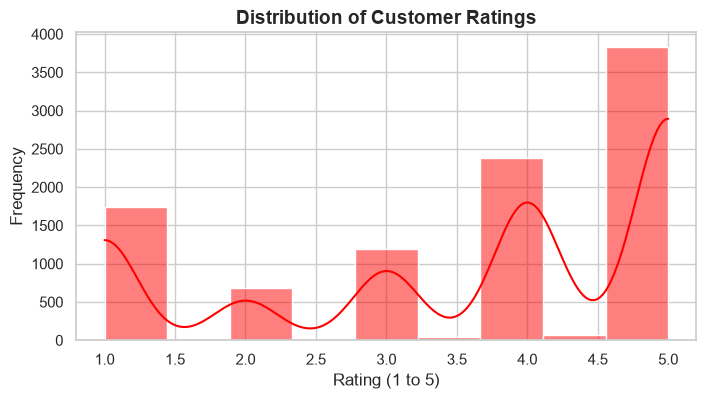

In [12]:
plt.figure(figsize=(8, 4))
sns.histplot(reviews_df["Rating_Clean"], bins=9, kde=True, color="Red")
plt.title("Distribution of Customer Ratings", fontsize=14, weight="bold")
plt.xlabel("Rating (1 to 5)")
plt.ylabel("Frequency")
plt.show()

### Visualization 2: Top 10 Rated Restaurants (Minimum sample threshold of reviews)

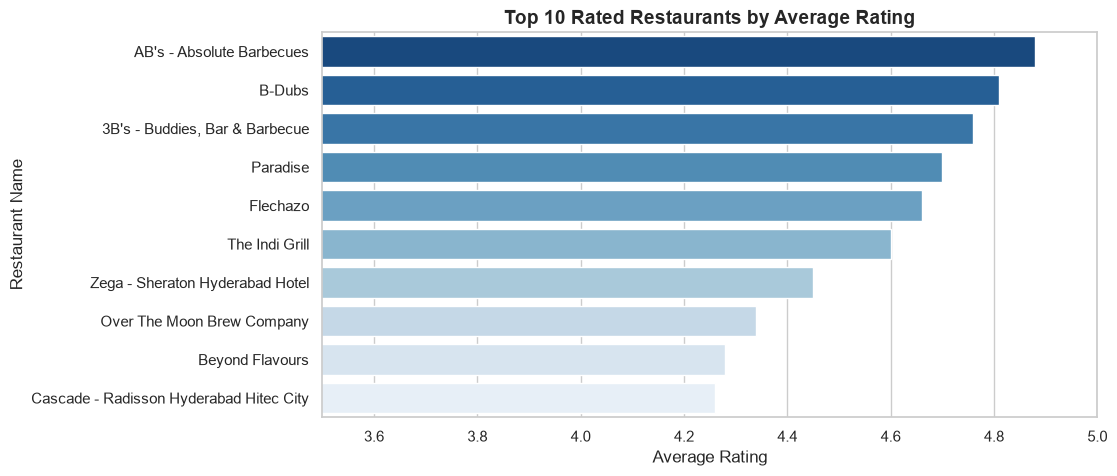

In [13]:
top_rated = (
    reviews_df.groupby("Restaurant")["Rating_Clean"]
    .agg(avg_rating="mean", review_count="count")
    .sort_values(by="avg_rating", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_rated["avg_rating"],
    y=top_rated.index,
    hue=top_rated.index,
    palette="Blues_r",
    legend=False
)
plt.xlim(3.5, 5.0)
plt.title("Top 10 Rated Restaurants by Average Rating", fontsize=14, weight="bold")
plt.xlabel("Average Rating")
plt.ylabel("Restaurant Name")
plt.show()

### Visualization 3: Most Common Cuisines

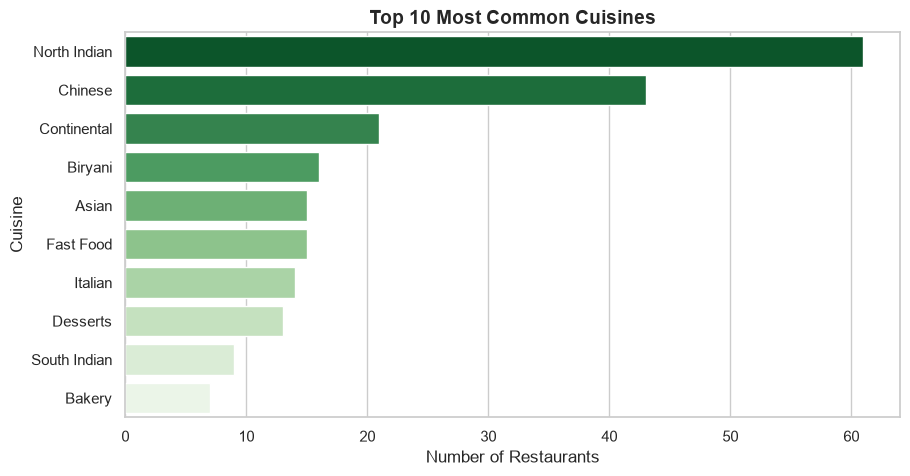

In [16]:
# Split comma-separated cuisine tags
all_cuisines = [
    c.strip()
    for sublist in metadata_df["Cuisines"].dropna().str.split(",")
    for c in sublist
]
top_cuisines = pd.Series(Counter(all_cuisines)).sort_values(ascending=False).head(10)

# plotting
plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index,
    hue=top_cuisines.index,
    palette="Greens_r",
    legend=False
)
plt.title("Top 10 Most Common Cuisines", fontsize=14, weight="bold")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")
plt.show()

# Visualization 4: Correlation Matrix And Cost vs. Rating

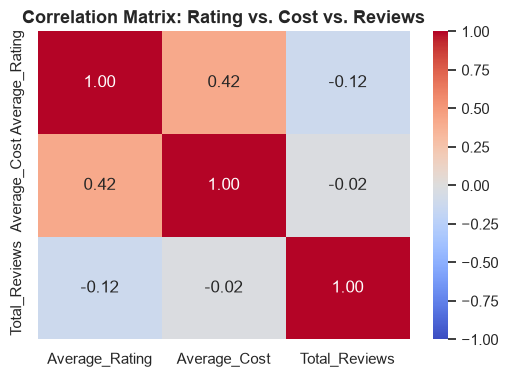

In [17]:
restaurant_stats = (
    merged_df.groupby("Restaurant")
    .agg(
        Average_Rating=("Rating_Clean", "mean"),
        Average_Cost=("Cost_Clean", "first"),
        Total_Reviews=("Review", "count"),
    )
    .dropna()
)

# plotting
plt.figure(figsize=(6, 4))
sns.heatmap(
    restaurant_stats.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix: Rating vs. Cost vs. Reviews", fontsize=13, weight="bold")
plt.show()

### Visualization 5: Scatter Plot: Cost vs Average Rating

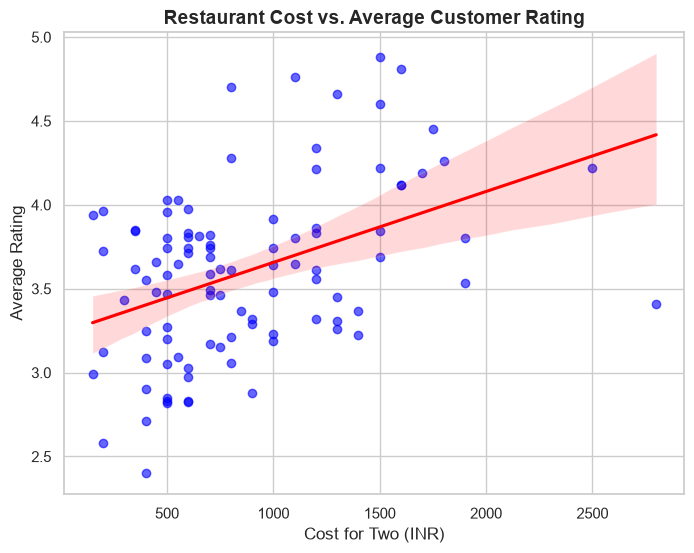

In [19]:
plt.figure(figsize=(8, 6))
sns.regplot(
    data=restaurant_stats,
    x="Average_Cost",
    y="Average_Rating",
    scatter_kws={"alpha": 0.6, "color": "blue"},
    line_kws={"color": "red"}
)
plt.title("Restaurant Cost vs. Average Customer Rating", fontsize=14, weight="bold")
plt.xlabel("Cost for Two (INR)")
plt.ylabel("Average Rating")
plt.show()

# NLP and ML part

## Importing necessory libraries

In [20]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

## 1. Loading and cleaning data

In [22]:
reviews_df = pd.read_csv(r'C:\aFiles And Media\DataAnalytics\HexaSolutions\Hexa Assignments\Assignments To Submit 09-10-2026\Zomato End to End EDA\9- Zomato End to End EDA\Zomato Project\Zomato Restaurant reviews.csv')
reviews_df.drop_duplicates(inplace=True)

# Drop missing reviews or ratings
reviews_df = reviews_df.dropna(subset=["Review", "Rating"]).copy()
reviews_df["Rating_Numeric"] = pd.to_numeric(
    reviews_df["Rating"], errors="coerce"
)
reviews_df = reviews_df.dropna(subset=["Rating_Numeric"])

## 2. Text Preprocessing Function (Cleaning, lowercasing, punctuation, regex)

In [23]:
def clean_review_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)  # Remove URLs
    text = re.sub(
        r"[^a-zA-Z\s]", " ", text
    )  # Remove punctuation, digits, symbols
    text = re.sub(r"\s+", " ", text).strip()  # Normalize whitespace
    return text


reviews_df["Cleaned_Review"] = reviews_df["Review"].apply(clean_review_text)

## 3. Sentiment Categorization (Ground Truth Mapping from Customer Ratings)

In [24]:
# >= 4.0 -> Positive | 3.0 to 3.5 -> Neutral | < 3.0 -> Negative
def map_rating_to_sentiment(rating: float) -> str:
    if rating >= 4.0:
        return "Positive"
    elif rating >= 3.0:
        return "Neutral"
    return "Negative"


reviews_df["Sentiment"] = reviews_df["Rating_Numeric"].apply(
    map_rating_to_sentiment
)

## 4. Train-Test Split with Stratification

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    reviews_df["Cleaned_Review"],
    reviews_df["Sentiment"],
    test_size=0.20,
    random_state=42,
    stratify=reviews_df["Sentiment"],
)

## 5. TF-IDF Vectorization (Unigrams + Bigrams, excluding English stopwords)

In [26]:
tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), stop_words="english")
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

## 6. Model Training: Logistic Regression (Balanced class weighting)

In [27]:
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_vec, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

## 7. Predictions And Evaluation Metrics

In [28]:
y_pred = model.predict(X_test_vec)
classes = ["Negative", "Neutral", "Positive"]

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=classes))

Classification Report:
              precision    recall  f1-score   support

    Negative       0.74      0.75      0.75       489
     Neutral       0.34      0.54      0.42       248
    Positive       0.92      0.81      0.86      1254

    accuracy                           0.76      1991
   macro avg       0.67      0.70      0.68      1991
weighted avg       0.80      0.76      0.78      1991



## 8. Confusion Matrix Visualization

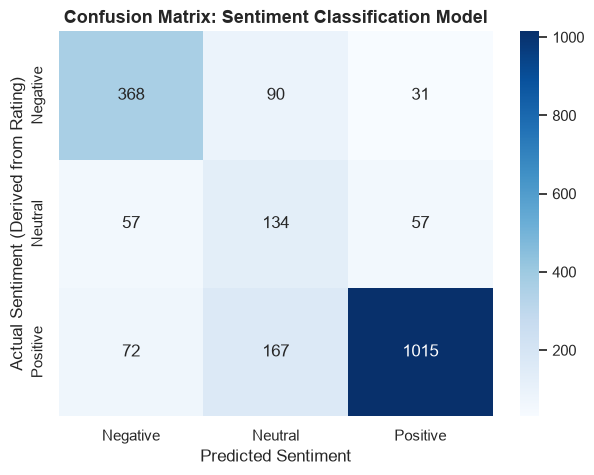

In [29]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
)
plt.title(
    "Confusion Matrix: Sentiment Classification Model", fontsize=13, weight="bold"
)
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment (Derived from Rating)")
plt.show()

## 9. Top Predictive Keywords per Category

In [30]:
feature_names = np.array(tfidf.get_feature_names_out())
for i, sentiment_label in enumerate(model.classes_):
    top_indices = np.argsort(model.coef_[i])[-8:]
    print(
        f"Top Indicative Words for '{sentiment_label}': {list(feature_names[top_indices])}"
    )

Top Indicative Words for 'Negative': ['bad experience', 'disappointed', 'poor', 'waste', 'horrible', 'bad', 'pathetic', 'worst']
Top Indicative Words for 'Neutral': ['fine', 'small', 'compared', 'okay', 'ok', 'average', 'better', 'ambience']
Top Indicative Words for 'Positive': ['thanks', 'excellent', 'delicious', 'loved', 'love', 'best', 'amazing', 'awesome']
